In [1]:
import pandas as pd

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv("/content/WA_Fn-UseC_-HR-Employee-Attrition.csv")

In [4]:
df.isnull()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1466,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1467,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1468,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [5]:
df.isnull().sum()

,0
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0


In [6]:
df=df.drop_duplicates()

In [7]:
print(df['Attrition'].value_counts())

Attrition
No     1233
Yes     237
Name: count, dtype: int64


In [8]:
df = df.drop(columns=['EmployeeCount', 'Over18', 'StandardHours'])

In [9]:
df.shape

(1470, 32)

In [10]:
print(df.groupby('Department')['Attrition'].value_counts())

Department              Attrition
Human Resources         No            51
                        Yes           12
Research & Development  No           828
                        Yes          133
Sales                   No           354
                        Yes           92
Name: count, dtype: int64


In [11]:
print(df.groupby(['Age', 'MonthlyIncome','OverTime'])['Attrition'].value_counts())

Age  MonthlyIncome  OverTime  Attrition
18   1051           No        No           1
     1200           No        No           1
     1420           No        Yes          1
     1514           No        No           1
     1569           Yes       Yes          1
                                          ..
60   5220           Yes       No           1
     5405           No        No           1
     10266          No        No           1
     10883          No        No           1
     19566          No        No           1
Name: count, Length: 1468, dtype: int64


In [12]:
pd.crosstab(df['Department'], df['Attrition'], normalize='index') * 100

Attrition,No,Yes
Department,,
Human Resources,80.952381,19.047619
Research & Development,86.160250,13.839750
Sales,79.372197,20.627803


In [13]:
df['Attrition_Numeric'] = df['Attrition'].map({'Yes': 1, 'No': 0})
for col in ['Department', 'OverTime', 'JobSatisfaction']:
    print(col)
    print((df.groupby(col)['Attrition_Numeric'].mean() * 100).round(1))
    print()

Department
Department
Human Resources           19.0
Research & Development    13.8
Sales                     20.6
Name: Attrition_Numeric, dtype: float64

OverTime
OverTime
No     10.4
Yes    30.5
Name: Attrition_Numeric, dtype: float64

JobSatisfaction
JobSatisfaction
1    22.8
2    16.4
3    16.5
4    11.3
Name: Attrition_Numeric, dtype: float64



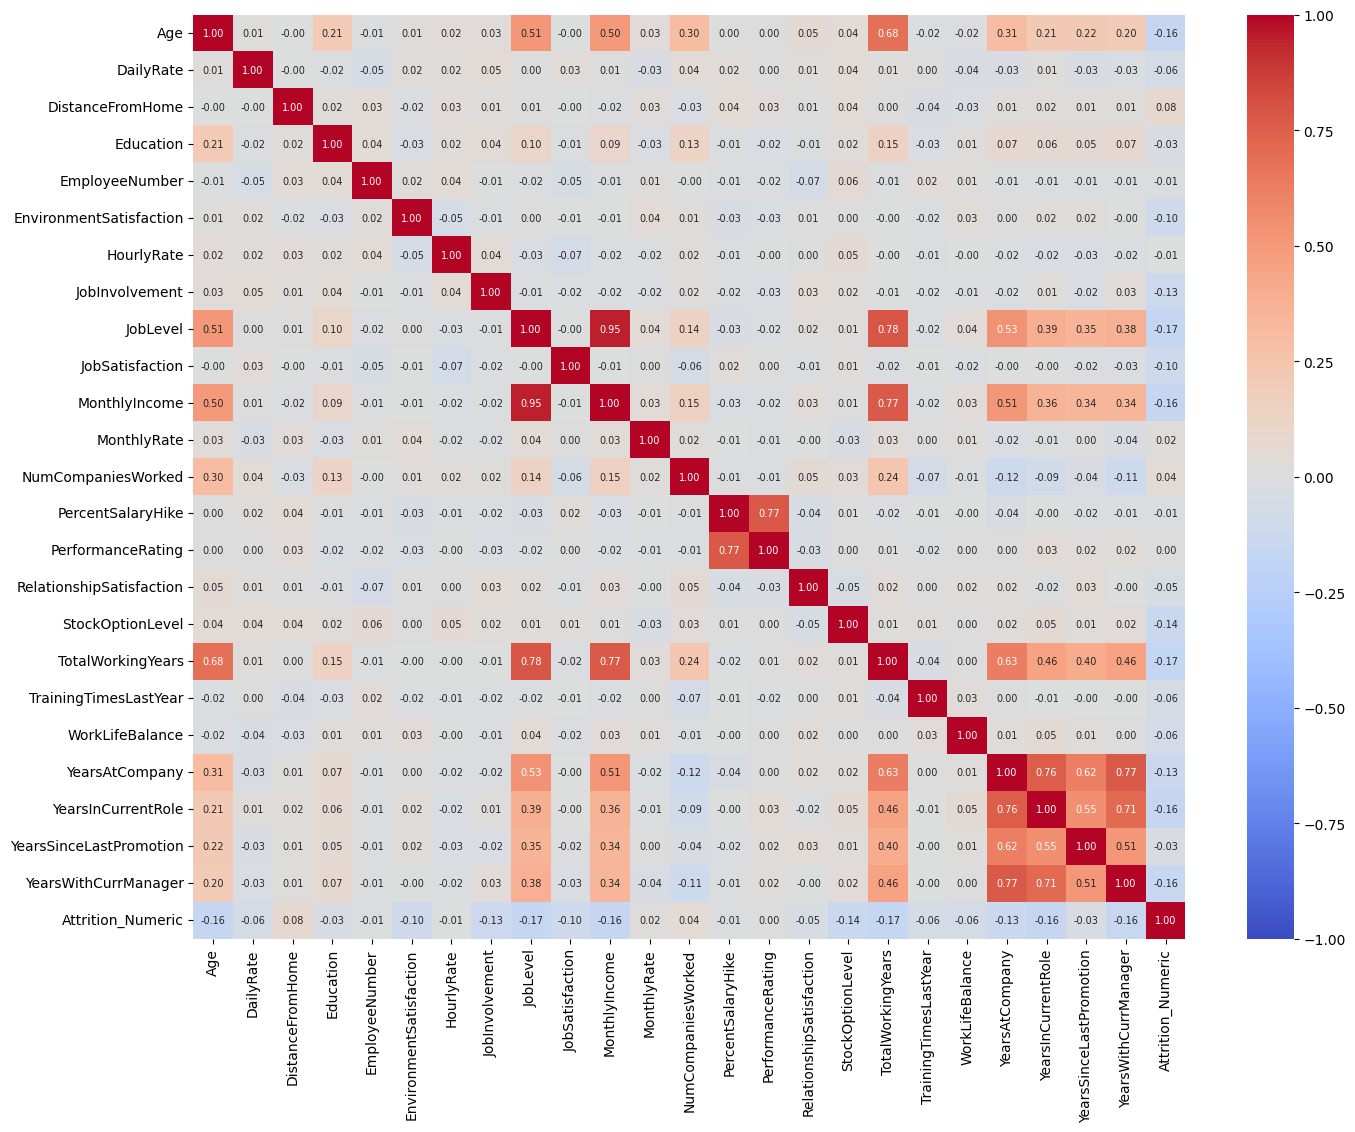

In [14]:
corr_mat=df.corr(numeric_only=True)
plt.figure(figsize=(16, 12))
sns.heatmap(corr_mat, annot=True, fmt='.2f', cmap='coolwarm', annot_kws={'size': 7}, vmin=-1, vmax=1)
plt.xticks(rotation=90)
plt.show()

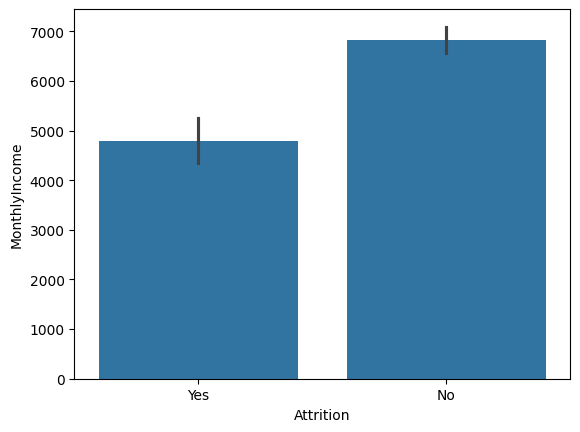

In [15]:
sns.barplot(x='Attrition', y='MonthlyIncome', data=df)
plt.show()

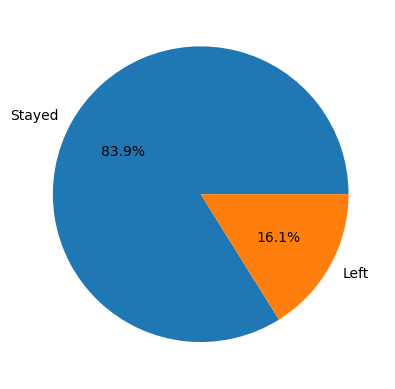

In [16]:
plt.pie(df['Attrition'].value_counts(), labels=['Stayed', 'Left'],autopct='%1.1f%%')
plt.show()

In [17]:
df['AttritionFlag'] = (df['Attrition'] == 'Yes').astype(int)
df['IncomeBand'] = pd.qcut(df['MonthlyIncome'], 4, labels=['Low', 'Mid', 'High', 'Top'])
df['TenureBand'] = pd.cut(df['YearsAtCompany'], [-1, 2, 5, 10, 50], labels=['0-2', '3-5', '6-10', '10+'])

for col in ['OverTime', 'IncomeBand', 'TenureBand']:
    print(df.groupby(col)['AttritionFlag'].agg(['sum', 'count', 'mean']))

          sum  count      mean
OverTime                      
No        110   1054  0.104364
Yes       127    416  0.305288
            sum  count      mean
IncomeBand                      
Low         108    369  0.292683
Mid          52    366  0.142077
High         39    367  0.106267
Top          38    368  0.103261
            sum  count      mean
TenureBand                      
0-2         102    342  0.298246
3-5          60    434  0.138249
6-10         55    448  0.122768
10+          20    246  0.081301


/tmp/ipykernel_579/3730335308.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby(col)['AttritionFlag'].agg(['sum', 'count', 'mean']))
/tmp/ipykernel_579/3730335308.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby(col)['AttritionFlag'].agg(['sum', 'count', 'mean']))


In [18]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report,accuracy_score


In [19]:
y = (df['Attrition'] == 'Yes').astype(int)
X = df.drop(columns=['Attrition', 'Attrition_Numeric', 'AttritionFlag'], errors='ignore')
X = pd.get_dummies(X, drop_first=True)

In [20]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [21]:
rf = RandomForestClassifier(class_weight='balanced', random_state=42)
rf.fit(Xtr, ytr)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [22]:
pred = rf.predict(Xte)
print(f"Accuracy Score: {accuracy_score(yte, pred):.4f}\n")
print(classification_report(yte, pred))

Accuracy Score: 0.8401

              precision    recall  f1-score   support

           0       0.85      0.99      0.91       247
           1       0.50      0.06      0.11        47

    accuracy                           0.84       294
   macro avg       0.67      0.53      0.51       294
weighted avg       0.79      0.84      0.78       294



In [24]:
from google.colab import files
df.to_csv("filtered_data.csv", index=False)
files.download("filtered_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>